# Setup

In [29]:
import os
import random
import sys
import socket
import platform
from pathlib import Path
from tempfile import TemporaryDirectory
from collections.abc import Sequence

os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"

import shutil
import zipfile
from tqdm.auto import tqdm

import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
import torch
from torch.utils.data import Dataset
from torch.utils.data import DataLoader


SEED = 67
def set_seed(seed: int = SEED) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


set_seed(SEED)
torch.backends.cudnn.benchmark = False
torch.use_deterministic_algorithms(True)

In [30]:
IN_COLAB = "COLAB_RELEASE_TAG" in os.environ
DATASET_IMAGE_NAME = "701_StillsRaw_full.zip"
DATASET_LABEL_NAME = "LabeledApproved_full.zip"

if IN_COLAB:
    DATASET_DIR = Path("/content/drive/MyDrive/IF4073_Pemrosesan_Citra_Digital/dataset")
    dataset_root = Path("/content/dataset")
    image_dir = dataset_root / "images"
    label_dir = dataset_root / "labels"
else:
    local_root = Path.cwd()
    if (local_root / "model" / "transfer-learning.ipynb").is_file():
        local_root = local_root / "model"

    DATASET_DIR = local_root / "dataset"
    image_dir = DATASET_DIR / Path(DATASET_IMAGE_NAME).stem
    label_dir = DATASET_DIR / Path(DATASET_LABEL_NAME).stem

## Runtime and dataset setup

In [31]:
print("Hostname:", socket.gethostname())
print("Operating system:", platform.system())
print("Python executable:", sys.executable)
print("Working directory:", os.getcwd())
print("Running in Colab:", IN_COLAB)
if torch.cuda.is_available():
    print(torch.cuda.get_device_name(0))
else:
    print("No GPU assigned")

Hostname: 3c4bde767f28
Operating system: Linux
Python executable: /usr/bin/python3
Working directory: /content
Running in Colab: True
Tesla T4


In [32]:
if IN_COLAB:
    import gdown

    archives = (
        ("14CRF7mrkHzZjvtVFLnaB0DjejFpRp945", DATASET_IMAGE_NAME, image_dir),
        ("1Nj6b_nSqfGl1W9XKnbXT08ZYDsTl0iTZ", DATASET_LABEL_NAME, label_dir),
    )

    for file_id, archive_name, folder in archives:
        if any(folder.rglob("*.png")):
            continue

        dataset_root.mkdir(parents=True, exist_ok=True)
        with TemporaryDirectory(dir=dataset_root) as temp_dir:
            zip_path = Path(temp_dir) / archive_name
            gdown.download(id=file_id, output=str(zip_path), use_cookies=False)
            if not zipfile.is_zipfile(zip_path):
                raise RuntimeError(f"Could not download {archive_name} as a ZIP.")

            with zipfile.ZipFile(zip_path) as archive:
                archive.extractall(folder)

for folder in (image_dir, label_dir):
    if not any(folder.rglob("*.png")):
        raise FileNotFoundError(f"No PNG files found in {folder}")
    print(f"Using {folder}")

Using /content/dataset/images
Using /content/dataset/labels


# Preprocessing

In [33]:
images = sorted(image_dir.rglob("*.png"))
if not images:
    raise FileNotFoundError(f"No PNG images found in {image_dir}")

pairs = [(image, label_dir / f"{image.stem}_L.png") for image in images]
for _, mask_path in pairs:
    if not mask_path.is_file():
        raise FileNotFoundError(f"Missing mask: {mask_path}")

In [34]:
# CamVid's annotation colors in hexadecimal RRGGBB format.
CAMVID_CLASSES = {
    (64, 128, 64): "Animal",
    (192, 0, 128): "Archway",
    (0, 128, 192): "Bicyclist",
    (0, 128, 64): "Bridge",
    (128, 0, 0): "Building",
    (64, 0, 128): "Car",
    (64, 0, 192): "CartLuggagePram",
    (192, 128, 64): "Child",
    (192, 192, 128): "Column_Pole",
    (64, 64, 128): "Fence",
    (128, 0, 192): "LaneMkgsDriv",
    (192, 0, 64): "LaneMkgsNonDriv",
    (128, 128, 64): "Misc_Text",
    (192, 0, 192): "MotorcycleScooter",
    (128, 64, 64): "OtherMoving",
    (64, 192, 128): "ParkingBlock",
    (64, 64, 0): "Pedestrian",
    (128, 64, 128): "Road",
    (128, 128, 192): "RoadShoulder",
    (0, 0, 192): "Sidewalk",
    (192, 128, 128): "SignSymbol",
    (128, 128, 128): "Sky",
    (64, 128, 192): "SUVPickupTruck",
    (0, 0, 64): "TrafficCone",
    (0, 64, 64): "TrafficLight",
    (192, 64, 128): "Train",
    (128, 128, 0): "Tree",
    (192, 128, 192): "Truck_Bus",
    (64, 0, 64): "Tunnel",
    (192, 192, 0): "VegetationMisc",
    (0, 0, 0): "Void",
    (64, 192, 0): "Wall",
}

IGNORE_INDEX = 255
class_colors = [rgb for rgb, name in CAMVID_CLASSES.items() if name != "Void"]
class_names = [CAMVID_CLASSES[rgb] for rgb in class_colors]
num_classes = len(class_names)

# Pack RGB into integer format used by load_mask().
color_to_class = {
    (red << 16) | (green << 8) | blue: class_id
    for class_id, (red, green, blue) in enumerate(class_colors)
}


def load_mask(mask_path: str | Path) -> np.ndarray[np.uint8]:
    mask_path = Path(mask_path)
    with Image.open(mask_path) as mask:
        rgb = np.asarray(mask.convert("RGB"), dtype=np.uint32)

    red, green, blue = rgb[..., 0], rgb[..., 1], rgb[..., 2]
    colors = (red << 16) | (green << 8) | blue

    target = np.full(colors.shape, IGNORE_INDEX, dtype=np.uint8)
    for color, class_id in color_to_class.items():
        target[colors == color] = class_id


    return target


print(f"Found {len(pairs)} image–mask pairs.")

print("Test image:")
_, mask_path = pairs[0]
target = load_mask(mask_path)
class_ids = np.unique(target[target != IGNORE_INDEX])
print(f"    Classes in {Path(mask_path).name}: {[class_names[i] for i in class_ids]}")
print(f"    Ignored pixels: {np.count_nonzero(target == IGNORE_INDEX)}")

Found 701 image–mask pairs.
Test image:
    Classes in 0001TP_006690_L.png: ['Building', 'Car', 'Column_Pole', 'LaneMkgsDriv', 'Misc_Text', 'OtherMoving', 'Pedestrian', 'Road', 'Sidewalk', 'Sky', 'SUVPickupTruck', 'TrafficLight', 'Tree', 'Truck_Bus']
    Ignored pixels: 28603


In [35]:
class CamVidDataset(Dataset):
    def __init__(
        self,
        pairs: Sequence[tuple[Path, Path]],
        image_size: tuple[int, int] | None = None,
    ) -> None:
        self.pairs = pairs
        self.image_size = image_size  # (height, width)
        self.mean = torch.tensor([0.485, 0.456, 0.406])[:, None, None]
        self.std = torch.tensor([0.229, 0.224, 0.225])[:, None, None]

    def __len__(self) -> int:
        return len(self.pairs)

    def __getitem__(self, index: int) -> tuple[torch.Tensor, torch.Tensor]:
        image_path, mask_path = self.pairs[index]

        with Image.open(image_path) as source:
            image = source.convert("RGB")
        mask = load_mask(mask_path)

        if self.image_size is not None: # then resize
            height, width = self.image_size
            size = (width, height)  # Pillow takes (width, height).
            image = image.resize(size, Image.Resampling.BILINEAR)
            mask = np.array(Image.fromarray(mask).resize(size, Image.Resampling.NEAREST))

        image_tensor = torch.from_numpy(np.array(image)).permute(2, 0, 1)
        image_tensor = (image_tensor.float() / 255.0 - self.mean) / self.std
        target = torch.from_numpy(mask.astype(np.int64))

        return image_tensor, target


image, target = CamVidDataset(pairs)[0]
print(image.shape, image.dtype)
print(target.shape, target.dtype)

torch.Size([3, 720, 960]) torch.float32
torch.Size([720, 960]) torch.int64


Images in a sequence (video) belong in one split. 

In [36]:
sequence_to_split = {
    "0016E5": "train",
    "Seq05VD": "train",
    "0001TP": "validation",
    "0006R0": "test",
}

splits = {"train": [], "validation": [], "test": []}
for image_path, mask_path in pairs:
    sequence = image_path.stem.split("_", 1)[0]
    splits[sequence_to_split[sequence]].append((image_path, mask_path))

image_size = None  # Keep 720 × 960. Set smaller if memory limit
batch_size = 4

loaders = {}
for split, split_pairs in splits.items():
    loaders[split] = DataLoader(
        CamVidDataset(split_pairs, image_size=image_size),
        batch_size=batch_size,
        shuffle=(split == "train"),
        num_workers=2,
        pin_memory=torch.cuda.is_available(),
    )
    print(f"{split}: {len(split_pairs)} images")

train_loader = loaders["train"]
validation_loader = loaders["validation"]
test_loader = loaders["test"]

train: 476 images
validation: 124 images
test: 101 images


# EDA

In [ ]:
def class_coverage(split_pairs):
    frame_counts = np.zeros(num_classes, dtype=np.int64)
    pixel_counts = np.zeros(num_classes, dtype=np.int64)
    sequences = [set() for _ in class_names]

    for image_path, mask_path in split_pairs:
        target = load_mask(mask_path)
        # Keep class IDs 0–30. This drops the ignore index (255).
        counts = np.bincount(target.ravel(), minlength=num_classes)[:num_classes]
        frame_counts += counts > 0
        pixel_counts += counts

        sequence = image_path.stem.split("_", 1)[0]
        for class_id in np.flatnonzero(counts):
            sequences[class_id].add(sequence)

    return frame_counts, pixel_counts, sequences


train_frames, train_pixels, train_sequences = class_coverage(splits["train"])
val_frames, _, _ = class_coverage(splits["validation"])
train_pixel_share = 100 * train_pixels / train_pixels.sum()

print(f"{'Class':20s} {'Train frames':>12s} {'Train pixels %':>14s} ", f"{'Train videos':>12s} {'Val frames':>10s}")
for i in np.argsort(train_frames):
    print(f"{class_names[i]:20s} {train_frames[i]:12d} {train_pixel_share[i]:14.5f} ", f"{len(train_sequences[i]):12d} {val_frames[i]:10d}")

Class                Train frames Train pixels %  Train videos Val frames
MotorcycleScooter               0        0.00000            0          0
Train                           0        0.00000            0          0
Tunnel                          1        0.00000            1          0
Bridge                          2        0.04598            1          0
TrafficCone                     4        0.00037            2          0
LaneMkgsNonDriv                21        0.02074            2          0
Animal                         25        0.00732            2          0
RoadShoulder                   43        0.32923            2         12
Archway                        99        0.02993            2          0
SUVPickupTruck                120        0.48209            2        118
ParkingBlock                  129        0.27537            2         29
Truck_Bus                     141        0.17146            1         43
Child                         156        0.04238  

# Fine-tuning

In [49]:
if IN_COLAB:
    import subprocess

    subprocess.run(
        [sys.executable, "-m", "pip", "install", "-q", "segmentation-models-pytorch==0.5.0"],
        check=True,
    )

In [50]:
import segmentation_models_pytorch as smp

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

freeze_encoder = True

model = smp.Unet(
    encoder_name="resnet34",
    encoder_weights=None,
    in_channels=3,
    classes=num_classes,
    activation=None,
).to(device)

checkpoint_root = Path(DATASET_DIR).parent / "checkpoints"
weighted_best_path = checkpoint_root / "camvid-unet-resnet34-weighted" / "best.pt"

checkpoint = torch.load(weighted_best_path, map_location="cpu", weights_only=True)
model.load_state_dict(checkpoint["model"])
print(f"Starting from weighted run epoch {checkpoint['epoch']}")
del checkpoint

model.encoder.requires_grad_(False)
model.encoder.layer4.requires_grad_(True)   # Last encoder layer

optimizer = torch.optim.AdamW([
    {"params": model.encoder.layer4.parameters(), "lr": 1e-5},
    {"params": model.decoder.parameters(), "lr": 1e-4},
    {"params": model.segmentation_head.parameters(), "lr": 1e-4},
])

print(f"U-Net with ResNet-34 | {num_classes} classes | {device}")

Starting from weighted run epoch 4
U-Net with ResNet-34 | 31 classes | cuda


In [51]:
use_amp = device.type == "cuda"
scaler = torch.amp.GradScaler("cuda", enabled=use_amp)


def run_epoch(loader: DataLoader, *, training: bool) -> float:
    model.train(training)
    if freeze_encoder:
        model.encoder.eval()
    total_loss = torch.zeros((), device=device)
    total_pixels = torch.zeros((), dtype=torch.long, device=device)

    with torch.set_grad_enabled(training):
        for images, targets in tqdm(loader, desc="Train" if training else "Validation"):
            images = images.to(device, non_blocking=True)
            targets = targets.to(device, non_blocking=True)

            if training:
                optimizer.zero_grad(set_to_none=True)

            with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
                logits = model(images)
                loss = criterion(logits, targets)

            if training:
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()

            valid_pixels = (targets != IGNORE_INDEX).sum()
            total_loss += loss.detach() * valid_pixels
            total_pixels += valid_pixels

    return (total_loss / total_pixels).item()

In [52]:
pixel_counts = np.zeros(num_classes, dtype=np.int64)

for _, mask_path in tqdm(splits["train"], desc="Counting training pixels"):
    target = load_mask(mask_path)
    labeled = target[target != IGNORE_INDEX]
    pixel_counts += np.bincount(labeled, minlength=num_classes)

present = pixel_counts > 0
median_count = np.median(pixel_counts[present])

weights = np.ones(num_classes, dtype=np.float64)
weights[present] = np.sqrt(median_count / pixel_counts[present])
weights = np.clip(weights, 0.5, 5.0)
weights /= np.average(weights, weights=pixel_counts)

class_weights = torch.tensor(weights, dtype=torch.float32, device=device)


def criterion(logits: torch.Tensor, targets: torch.Tensor) -> torch.Tensor:
    valid = targets != IGNORE_INDEX
    safe_targets = targets.masked_fill(~valid, 0)

    log_probs = logits.float().log_softmax(dim=1)
    pixel_loss = -log_probs.gather(1, safe_targets.unsqueeze(1)).squeeze(1)

    if model.training:
        pixel_loss = pixel_loss * class_weights[safe_targets]

    return pixel_loss.masked_fill(~valid, 0).sum() / valid.sum().clamp_min(1)


print("Class-weighted training loss is active.")

Counting training pixels:   0%|          | 0/476 [00:00<?, ?it/s]

Class-weighted training loss is active.


Training setups. Use different run_dir for testing different settings

In [55]:
epochs = 30
patience = 7
run_dir = Path(DATASET_DIR).parent / "checkpoints" / "camvid-unet-resnet34-weighted-layer4unfrozen"
run_dir.mkdir(parents=True, exist_ok=True)
latest_path = run_dir / "latest.pt"
best_path = run_dir / "best.pt"

In [56]:
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode="min", factor=0.5, patience=2
)


def save_checkpoint(state: dict, path: Path) -> None:
    temporary_path = path.with_suffix(".tmp")
    torch.save(state, temporary_path)
    temporary_path.replace(path)


start_epoch = 1
best_epoch = 0
best_loss = float("inf")
history = []

if latest_path.is_file():
    state = torch.load(latest_path, map_location="cpu", weights_only=True)
    model.load_state_dict(state["model"])
    optimizer.load_state_dict(state["optimizer"])
    scheduler.load_state_dict(state["scheduler"])
    if use_amp and state["scaler"]:
        scaler.load_state_dict(state["scaler"])

    start_epoch = state["epoch"] + 1
    best_epoch = state["best_epoch"]
    best_loss = state["best_loss"]
    history = state["history"]

    # Recover best.pt if the runtime disconnected between saves.
    if state["epoch"] == best_epoch:
        save_checkpoint(state, best_path)

    del state
    print(f"Resuming at epoch {start_epoch}")

for epoch in range(start_epoch, epochs + 1):
    if epoch - 1 - best_epoch >= patience:
        print(f"Early stopping. Best epoch was {best_epoch}.")
        break

    train_loss = run_epoch(train_loader, training=True)
    validation_loss = run_epoch(validation_loader, training=False)
    scheduler.step(validation_loss)
    history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "validation_loss": validation_loss,
    })

    improved = validation_loss < best_loss
    if improved:
        best_loss = validation_loss
        best_epoch = epoch

    state = {
        "epoch": epoch,
        "model": model.state_dict(),
        "optimizer": optimizer.state_dict(),
        "scheduler": scheduler.state_dict(),
        "scaler": scaler.state_dict(),
        "best_epoch": best_epoch,
        "best_loss": best_loss,
        "history": history,
    }
    save_checkpoint(state, latest_path)
    if improved:
        save_checkpoint(state, best_path)

    print(f"Epoch {epoch}/{epochs} | train {train_loss:.4f} | val {validation_loss:.4f}")

Train:   0%|          | 0/119 [00:00<?, ?it/s]

Validation:   0%|          | 0/31 [00:00<?, ?it/s]

Epoch 1/30 | train 0.3281 | val 1.3762


Train:   0%|          | 0/119 [00:00<?, ?it/s]

Validation:   0%|          | 0/31 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7e8c8da67600>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7e8c8da67600>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

... (19 outputs left out)

Epoch 8/30 | train 0.1681 | val 1.6183


Train:   0%|          | 0/119 [00:00<?, ?it/s]

Validation:   0%|          | 0/31 [00:00<?, ?it/s]

Epoch 9/30 | train 0.1581 | val 1.6587
Early stopping. Best epoch was 2.


# Test

In [57]:
checkpoint = torch.load(best_path, map_location="cpu", weights_only=True)
model.load_state_dict(checkpoint["model"])
print(f"Evaluating epoch {checkpoint['epoch']}")
del checkpoint

model.eval()
confusion = torch.zeros(
    (num_classes, num_classes), dtype=torch.long, device=device
)

with torch.inference_mode():
    for images, targets in tqdm(test_loader, desc="Test"):
        images = images.to(device)
        targets = targets.to(device)

        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
            predictions = model(images).argmax(dim=1)

        valid = targets != IGNORE_INDEX
        # Rows are true classes. Columns are predicted classes.
        indices = targets[valid] * num_classes + predictions[valid]
        confusion += torch.bincount(
            indices, minlength=num_classes ** 2
        ).reshape(num_classes, num_classes)

confusion = confusion.cpu()
correct = confusion.diag()
actual = confusion.sum(dim=1)
predicted = confusion.sum(dim=0)
union = actual + predicted - correct
included = union > 0

iou = correct / union.clamp_min(1)
dice = 2 * correct / (actual + predicted).clamp_min(1)
precision = correct / predicted.clamp_min(1)
recall = correct / actual.clamp_min(1)

print(f"Pixel accuracy: {correct.sum() / confusion.sum():.2%}")
print(f"Mean IoU:       {iou[included].mean():.2%}")
print(f"Mean Dice:      {dice[included].mean():.2%}")
print(f"Mean precision: {precision[included].mean():.2%}")
print(f"Mean recall:    {recall[included].mean():.2%}")

print("\nPer-class IoU")
for name, score, present in zip(class_names, iou, included):
    if present:
        print(f"{name:20s} {score:.2%}")

Evaluating epoch 2


Test:   0%|          | 0/26 [00:00<?, ?it/s]

Pixel accuracy: 84.08%
Mean IoU:       23.72%
Mean Dice:      30.31%
Mean precision: 32.06%
Mean recall:    33.90%

Per-class IoU
Animal               0.00%
Archway              0.00%
Bicyclist            0.00%
Bridge               0.00%
Building             68.74%
Car                  71.35%
CartLuggagePram      0.00%
Child                0.00%
Column_Pole          26.61%
Fence                20.61%
LaneMkgsDriv         64.00%
Misc_Text            4.08%
MotorcycleScooter    0.00%
OtherMoving          18.81%
ParkingBlock         0.03%
Pedestrian           24.13%
Road                 89.80%
RoadShoulder         0.00%
Sidewalk             29.28%
SignSymbol           17.31%
Sky                  89.56%
SUVPickupTruck       10.21%
TrafficCone          0.00%
TrafficLight         3.24%
Tree                 74.48%
Truck_Bus            0.00%
VegetationMisc       41.95%
Wall                 9.93%


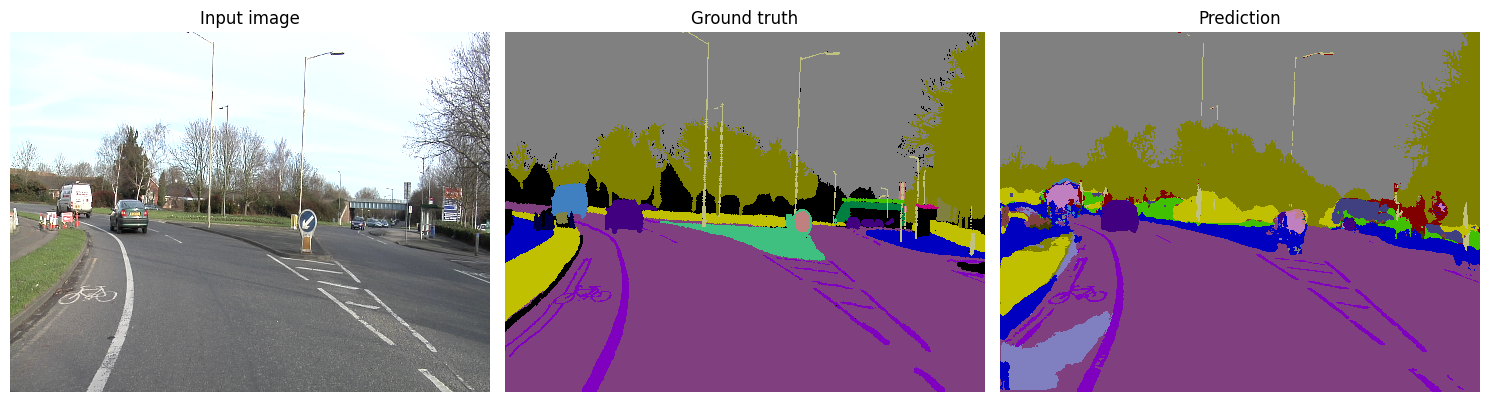

In [58]:
sample_index = 0
test_dataset = test_loader.dataset
image, target = test_dataset[sample_index]

model.eval()
with torch.inference_mode():
    with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
        logits = model(image.unsqueeze(0).to(device))
    prediction = logits.argmax(dim=1)[0].cpu().numpy()

# Undo ImageNet normalization for display.
rgb = (image * test_dataset.std + test_dataset.mean).clamp(0, 1)
rgb = rgb.permute(1, 2, 0).numpy()

# Map class IDs back to RGB. The ignore index stays black.
palette = np.zeros((256, 3), dtype=np.uint8)
palette[:num_classes] = class_colors

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, title, pixels in zip(
    axes,
    ("Input image", "Ground truth", "Prediction"),
    (rgb, palette[target.numpy()], palette[prediction]),
):
    ax.imshow(pixels, interpolation="nearest")
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()